# Dados e Aprendizagem Automática 26/27
### Part VIII

## **Multi Layer Percepreton using Titanic Dataset - Model 1**

#### Imports, installations and settings

Install Pytorch: https://pytorch.org/get-started/locally/

In [2]:
!pip install torch torchinfo livelossplot

In [3]:
import sklearn as skl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from torch import Tensor
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torch.utils.data import random_split
from torch.nn import Module, Linear, ReLU, Softmax, CrossEntropyLoss
from torchinfo import summary
from torch.optim import SGD, Adam

from IPython.display import display

from livelossplot import PlotLosses

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

%matplotlib inline

device = torch.device("cpu")

In [4]:
print(torch.__version__)

2.15.0+cu132


#### Titanic Dataset

Load the CSV - *Titanic*

In [5]:
t = pd.read_csv('../titanic_ds.csv')

**Target: *Pclass***

In [6]:
df_X = t.drop('Pclass', axis=1)
df_X.head()

,PassengerId,Survived,Sex,Age,SibSp,Parch,Fare,Embarked
0,1,0,1,22.0,1,0,7.2500,2
1,2,1,0,38.0,1,0,71.2833,0
2,3,1,0,26.0,0,0,7.9250,2
3,4,1,0,35.0,1,0,53.1000,2
4,5,0,1,35.0,0,0,8.0500,2


In [7]:
t_X = pd.DataFrame(df_X)
filename = "titanic_X.csv"
t_X.to_csv(filename, index=False, encoding='utf-8')

In [8]:
df_y = t['Pclass']
df_y.head()

0    3
1    1
2    3
3    1
4    3
Name: Pclass, dtype: int64

In [9]:
t_y = pd.DataFrame(df_y)
filename = "titanic_y.csv"
t_y.to_csv(filename, index=False, encoding='utf-8')

#### Data Preparation

In [10]:
class CSVDataset():
    def __init__(self):
        df_X = pd.read_csv("titanic_X.csv", header=0)
        df_y = pd.read_csv("titanic_y.csv", header=0)
        self.X = df_X.values
        self.y = df_y.values[:, 0]-1   # Pclass 1,2,3 -> classes 0,1,2
        self.X = self.X.astype('float32')
        self.y = torch.tensor(self.y, dtype=torch.long, device=device)
        print(self.X.shape)
        print(self.y.shape)
        print(self.X.ndim)
        print(self.y.ndim)
        print(self.X.dtype)
        print(self.y.dtype)
        
    def __len__(self):
        return len(self.X)
 
    def __getitem__(self, idx):
        return [self.X[idx], self.y[idx]]
 
    def get_splits(self, n_test, n_val):
        test_size = round(n_test * len(self.X))
        val_size = round(n_val * len(self.X))
        train_size = len(self.X) - (test_size + val_size)
        return random_split(self, [train_size, test_size, val_size])
    
def prepare_data(n_test, n_val):
    dataset = CSVDataset()
    train, test, val = dataset.get_splits(n_test, n_val)
    train_dl = DataLoader(train, batch_size=len(train), shuffle=True)
    test_dl = DataLoader(test, batch_size=len(test), shuffle=True)
    val_dl = DataLoader(val, batch_size=len(val), shuffle=True)
    return train_dl, test_dl, val_dl

In [11]:
train_dl, test_dl, val_dl = prepare_data(0.1, 0.2)

(891, 8)
torch.Size([891])
2
1
float32
torch.int64


#### Data Balance

In [12]:
def visualize_dataset(train_dl, test_dl, val_dl):
    print(f"Train size:{len(train_dl.dataset)}") 
    print(f"Test size:{len(test_dl.dataset)}")
    print(f"Validation size:{len(val_dl.dataset)}")
    x, y = next(iter(train_dl)) 
    print(f"Shape tensor train data batch - input: {x.shape}, output: {y.shape}")
    x, y = next(iter(test_dl))  
    print(f"Shape tensor test data batch - input: {x.shape}, output: {y.shape}")
    x, y = next(iter(val_dl))  
    print(f"Shape tensor validation data batch - input: {x.shape}, output: {y.shape}")

In [13]:
visualize_dataset(train_dl, test_dl, val_dl)

Train size:624
Test size:89
Validation size:178
Shape tensor train data batch - input: torch.Size([624, 8]), output: torch.Size([624])
Shape tensor test data batch - input: torch.Size([89, 8]), output: torch.Size([89])
Shape tensor validation data batch - input: torch.Size([178, 8]), output: torch.Size([178])


In [14]:
def visualize_holdout_balance(train_dl, test_dl, val_dl):
    _, y_train = next(iter(train_dl))                            
    _, y_test = next(iter(test_dl))
    _, y_val = next(iter(val_dl))
    
    sns.set_style('whitegrid')
    train_df = len(y_train) 
    test_df = len(y_test)
    val_df = len(y_val)
    Class_1_train = np.count_nonzero(y_train == 0)
    Class_2_train = np.count_nonzero(y_train == 1)
    Class_3_train = np.count_nonzero(y_train == 2)
    print("train data: ", train_df)
    print("Class 1: ", Class_1_train) 
    print("Class 2: ", Class_2_train)
    print("Class 3: ", Class_3_train)
    print("Values' mean (train): ", np.mean(y_train.numpy()))

    Class_1_test = np.count_nonzero(y_test == 0)
    Class_2_test = np.count_nonzero(y_test == 1)
    Class_3_test = np.count_nonzero(y_test == 2)
    print("test data: ", test_df)
    print("Class 1: ", Class_1_test) 
    print("Class 2: ", Class_2_test)
    print("Class 3: ", Class_3_test)
    print("Values' mean (test): ", np.mean(y_test.numpy()))

    Class_1_val = np.count_nonzero(y_val == 0)
    Class_2_val = np.count_nonzero(y_val == 1)
    Class_3_val = np.count_nonzero(y_val == 2)
    print("validation data: ", val_df)
    print("Class 1: ", Class_1_val) 
    print("Class 2: ", Class_2_val)
    print("Class 3: ", Class_3_val)
    print("Values' mean (val): ", np.mean(y_val.numpy()))

    graph = sns.barplot(x=['Class 1 train', 'Class 2 train', 'Class 3 train',
                           'Class 1 test', 'Class 2 test', 'Class 3 test', 
                           'Class 1 val', 'Class 2 val', 'Class 3 val'], 
                        y=[Class_1_train, Class_2_train, Class_3_train,
                           Class_1_test, Class_2_test, Class_3_test,
                           Class_1_val, Class_2_val, Class_3_val])
    
    graph.set_title('Data balance by class')
    plt.xticks(rotation=70)
    plt.tight_layout()
    plt.savefig('data_balance_MLP.png')
    plt.show()


    graph = sns.barplot(x=['Train data average','Test data average', 'Validation data average'], 
                        y=[np.mean(y_train.numpy()), np.mean(y_test.numpy()), np.mean(y_val.numpy())])
    graph.set_title('Data balance by mean')
    plt.xticks(rotation=70)
    plt.tight_layout()
    plt.show()

train data:  624
Class 1:  150
Class 2:  129
Class 3:  345
Values' mean (train):  1.3125
test data:  89
Class 1:  25
Class 2:  21
Class 3:  43
Values' mean (test):  1.202247191011236
validation data:  178
Class 1:  41
Class 2:  34
Class 3:  103
Values' mean (val):  1.348314606741573


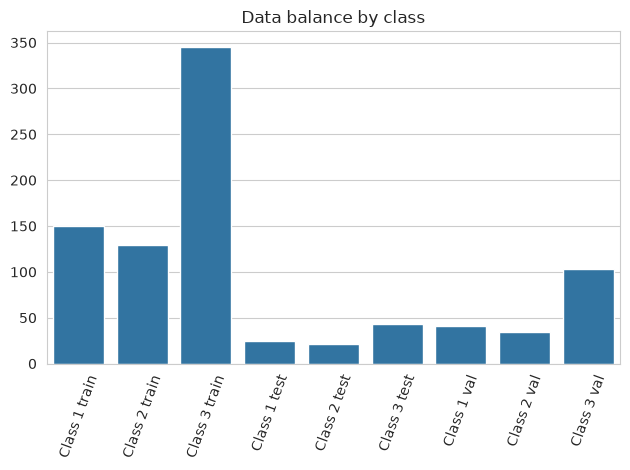

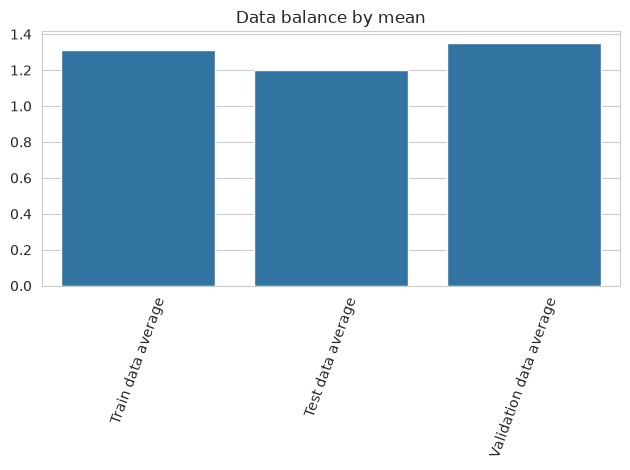

In [15]:
visualize_holdout_balance(train_dl, test_dl, val_dl)

#### MLP Model 1

- feedforward network with fully interconnected layers
- **epochs**: 200
- **learning rate**: 0.001
- **layers**: 3 Linear
- **activation fuctions**: ReLU and Softmax
- **loss**: CrossEntropyLoss
- **optimiser**: SGD

In [16]:
EPOCHS = 200
LEARNING_RATE = 0.001

In [17]:
class MLP_1(Module):
    def __init__(self, n_inputs):
        super(MLP_1, self).__init__()
        self.hidden1 = Linear(n_inputs, 24)
        self.hidden2 = Linear(24, 12)
        self.hidden3 = Linear(12, 3)
        self.act1 = ReLU()
        self.act2 = Softmax(dim=1)

    def forward(self, X):
        X = self.hidden1(X)
        X = self.act1(X)
        X = self.hidden2(X)
        X = self.act1(X)
        X = self.hidden3(X)
        X = self.act2(X)
        return X

Define the neural network

In [18]:
model = MLP_1(8)

Visualize the network

In [19]:
print(summary(model, input_size=(len(train_dl.dataset), 8), verbose=0))
model.to(device)

Layer (type:depth-idx)                   Output Shape              Param #
MLP_1                                    [624, 3]                  --
├─Linear: 1-1                            [624, 24]                 216
├─ReLU: 1-2                              [624, 24]                 --
├─Linear: 1-3                            [624, 12]                 300
├─ReLU: 1-4                              [624, 12]                 --
├─Linear: 1-5                            [624, 3]                  39
├─Softmax: 1-6                           [624, 3]                  --
Total params: 555
Trainable params: 555
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.35
Input size (MB): 0.02
Forward/backward pass size (MB): 0.19
Params size (MB): 0.00
Estimated Total Size (MB): 0.22


MLP_1(
  (hidden1): Linear(in_features=8, out_features=24, bias=True)
  (hidden2): Linear(in_features=24, out_features=12, bias=True)
  (hidden3): Linear(in_features=12, out_features=3, bias=True)
  (act1): ReLU()
  (act2): Softmax(dim=1)
)

#### Train the model

In [20]:
def train_model(train_dl, val_dl, model):
    liveloss = PlotLosses()
    criterion = CrossEntropyLoss()
   
    optimizer = SGD(model.parameters(), lr=LEARNING_RATE, momentum=0.9)

    for epoch in range(EPOCHS):
        logs = {} 
        model.train()
        running_loss  = 0.0
        running_corrects  = 0.0
        for inputs, labels in train_dl: 
            inputs = inputs.to(device)
            labels = labels.to(device)
            
            outputs = model(inputs)
            
            loss = criterion(outputs, labels)
            optimizer.zero_grad() 
            loss.backward()
            optimizer.step()
            running_loss += loss.detach() * inputs.size(0)
            
            _, preds = torch.max(outputs, 1)
            running_corrects += torch.sum(preds == labels.data)
        
        epoch_loss = running_loss / len(train_dl.dataset)
        epoch_acc = running_corrects.float() / len(train_dl.dataset)
        logs['loss'] = epoch_loss.item()
        logs['accuracy'] = epoch_acc.item()

        model.eval()
        running_loss_val  = 0.0
        running_corrects_val  = 0.0
        for inputs, labels in val_dl: 
            inputs = inputs.to(device)
            labels = labels.to(device)
            
            outputs = model(inputs)
            
            loss_val = criterion(outputs, labels)
            running_loss_val += loss_val.detach() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            running_corrects_val += torch.sum(preds == labels.data)
        
        epoch_loss_val = running_loss_val / len(val_dl.dataset)
        epoch_acc_val = running_corrects_val.float() / len(val_dl.dataset)
        logs['val_loss'] = epoch_loss_val.item()
        logs['val_accuracy'] = epoch_acc_val.item()    
        liveloss.update(logs)
        liveloss.send()

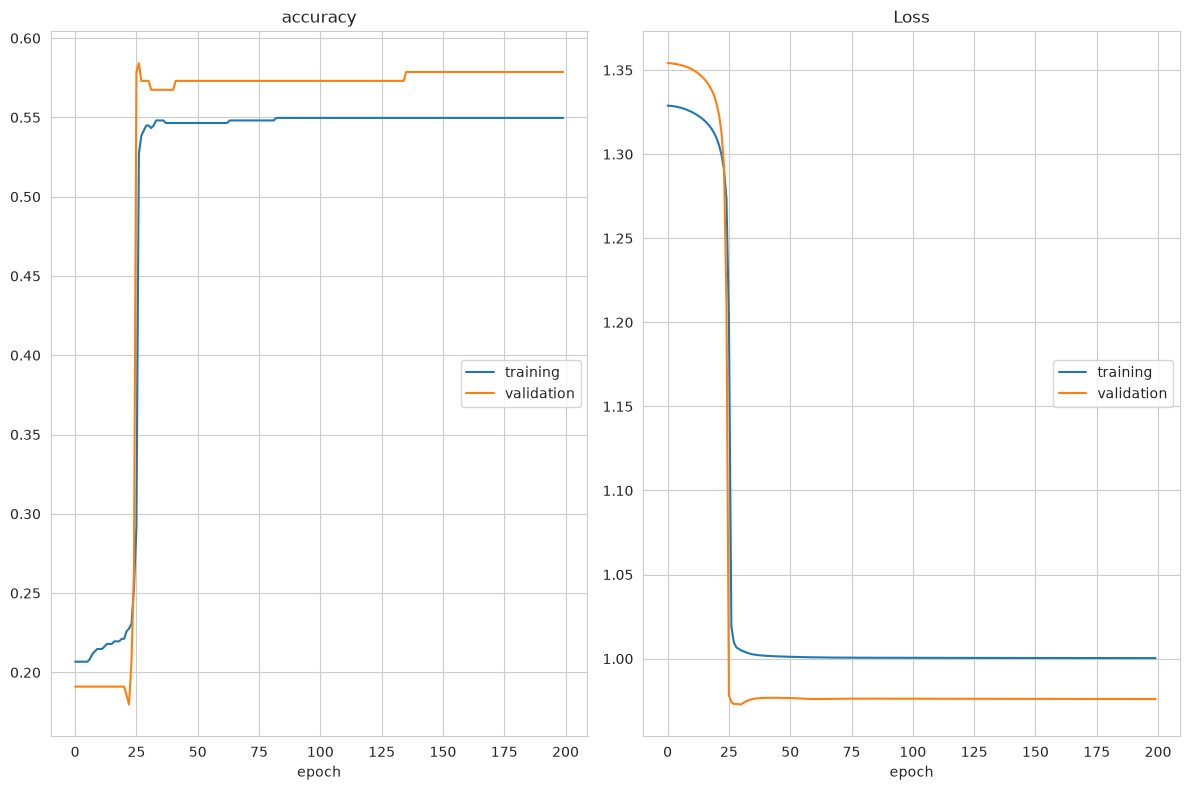

accuracy
	training         	 (min:    0.207, max:    0.550, cur:    0.550)
	validation       	 (min:    0.180, max:    0.584, cur:    0.579)
Loss
	training         	 (min:    1.000, max:    1.329, cur:    1.000)
	validation       	 (min:    0.973, max:    1.354, cur:    0.976)


In [21]:
train_model(train_dl, val_dl, model)

#### Evaluate the model

In [22]:
def evaluate_model(test_dl, model):
    predictions = list()
    actual_values = list()
    for i, (inputs, labels) in enumerate(test_dl):
        yprev = model(inputs)
        yprev = yprev.detach().numpy()
        actual = labels.numpy()
        yprev = np.argmax(yprev, axis=1)
        actual = actual.reshape((len(actual), 1))
        yprev = yprev.reshape((len(yprev), 1))
        predictions.append(yprev)
        actual_values.append(actual)
        break
    predictions, actual_values = np.vstack(predictions), np.vstack(actual_values)
    return predictions, actual_values

In [23]:
def display_confusion_matrix(cm):
    plt.figure(figsize = (16,8))
    sns.heatmap(cm, annot=True, xticklabels=['Class 1', 'Class 2', 'Class 3'],
                yticklabels=['Class 1', 'Class 2', 'Class 3'], 
                annot_kws={"size": 12}, fmt='g', linewidths=.5)
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show()

In [24]:
predictions, actual_values = evaluate_model(test_dl, model)

In [25]:
success = 0
failure = 0
for r,p in zip(actual_values, predictions):
    print(f'real:{r+1} prediction:{p+1}') 
    if r==p: success+=1  
    else: failure+=1

real:[3] prediction:[3]
real:[1] prediction:[3]
real:[3] prediction:[3]
real:[2] prediction:[3]
real:[3] prediction:[2]
real:[2] prediction:[3]
real:[3] prediction:[3]
real:[3] prediction:[3]
real:[2] prediction:[3]
real:[1] prediction:[3]
real:[2] prediction:[3]
real:[3] prediction:[3]
real:[3] prediction:[3]
real:[3] prediction:[3]
real:[2] prediction:[3]
real:[1] prediction:[3]
real:[1] prediction:[3]
real:[3] prediction:[3]
real:[3] prediction:[3]
real:[3] prediction:[3]
real:[2] prediction:[3]
real:[1] prediction:[3]
real:[1] prediction:[3]
real:[1] prediction:[3]
real:[3] prediction:[3]
real:[3] prediction:[3]
real:[3] prediction:[3]
real:[3] prediction:[3]
real:[1] prediction:[3]
real:[2] prediction:[3]
real:[2] prediction:[3]
real:[2] prediction:[3]
real:[2] prediction:[3]
real:[3] prediction:[3]
real:[3] prediction:[3]
real:[1] prediction:[3]
real:[1] prediction:[3]
real:[2] prediction:[3]
real:[1] prediction:[3]
real:[3] prediction:[3]
real:[1] prediction:[3]
real:[1] predict

In [26]:
acc = accuracy_score(actual_values, predictions)
print(f'Accuracy: {acc:0.3f}\n')
print(f'success:{success} failure:{failure}')

Accuracy: 0.472

success:42 failure:47


              precision    recall  f1-score   support

           0       0.00      0.00      0.00        25
           1       0.00      0.00      0.00        21
           2       0.48      0.98      0.64        43

    accuracy                           0.47        89
   macro avg       0.16      0.33      0.21        89
weighted avg       0.23      0.47      0.31        89

[[ 0  0 25]
 [ 0  0 21]
 [ 0  1 42]]


/home/ivocs/miniconda3/envs/daa_env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/ivocs/miniconda3/envs/daa_env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/ivocs/miniconda3/envs/daa_env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metri

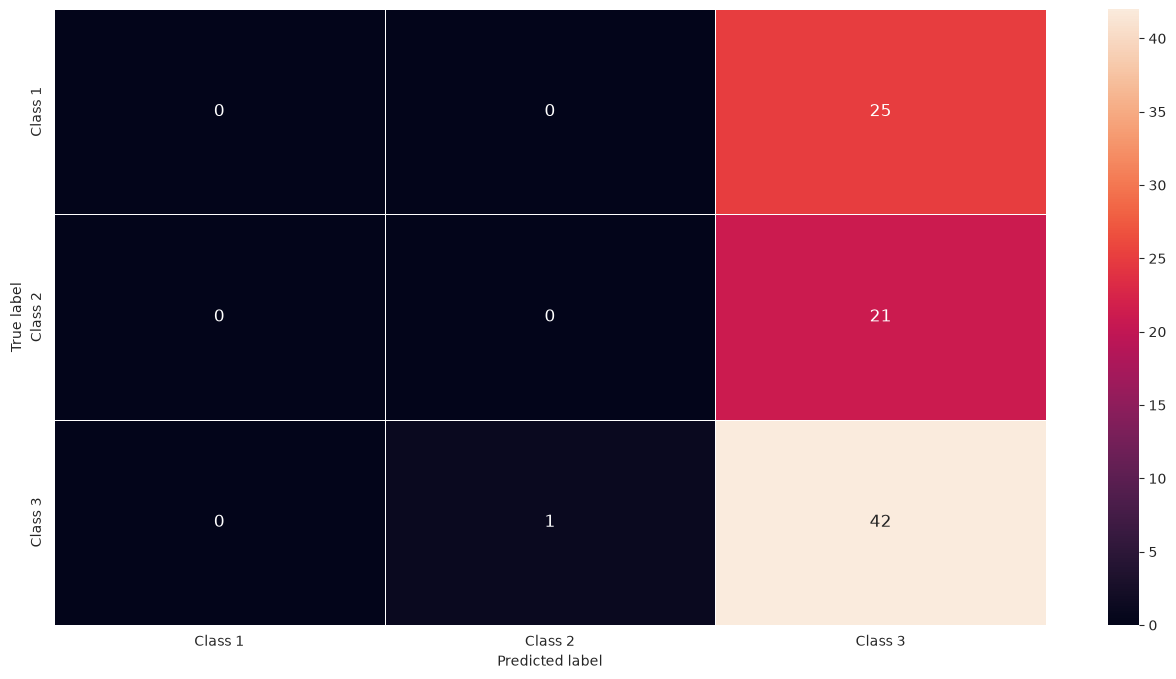

In [27]:
print(classification_report(actual_values, predictions))
cm = confusion_matrix(actual_values, predictions)
print(cm)
display_confusion_matrix(cm)

#### Apply the model

Make a prediction using one case:

In [28]:
def predict(row, model):
    row = Tensor([row])
    yprev = model(row)
    yprev = yprev.detach().numpy()
    return yprev

In [29]:
row = [5, 0, 1, 34, 0, 1, 8, 1]
yprev = predict(row, model)
print('Predicted: %s (class=%d)' % (yprev, np.argmax(yprev)+1))

Predicted: [[0.02570559 0.47213858 0.50215584]] (class=3)


#### Conclusões
Configuração base (sem inicialização explícita, sem normalização, CrossEntropyLoss e SGD). Nos slides obtém **accuracy ≈ 0.730** no conjunto de teste. É a referência para os modelos seguintes.

Nota: a `CrossEntropyLoss` já aplica internamente `log_softmax`. Ao usar `Softmax` na última camada, o softmax é aplicado duas vezes, o que achata os gradientes e torna o treino mais lento. Mantemos esta configuração para seguir a aula.